# 第 3 课｜职位文本分析与技能特征

**90 分钟：文本处理 20′ → 技能词典与关键词 30′ → 特征分析 30′ → 抽查 10′**

目标：把职责与要求变成可分析特征。使用可解释技能词典，并用 TF-IDF 探索额外关键词。
“文本提及”不等于“必须掌握”；没有提及也不代表不需要。先分开职责/要求，再分析合并文本。

> **增强版阅读方法**：先看本节问题，预测输出，再运行代码，最后解释数字。
> 关键代码已加中文注释，说明“为什么做、参数是什么、结果的行列单位是什么”。
> 标有【主线】的段落用于课堂；【拓展】用于教师演示或课后，不要求90分钟内完成所有扩展。
> 长代码按完整步骤拆成较短单元；每本仍需从上到下依次运行。

In [1]:
# Path把文件路径当作对象处理；用 / 拼接路径可兼容不同操作系统。
from pathlib import Path
import sys, json, re
# NumPy处理数组和数值；np只是约定俗成的简称，不是Python关键字。
import numpy as np
# Pandas处理带行列标签的表格；Series是一列，DataFrame是一张表。
import pandas as pd
# display显示表格，Markdown把动态生成的结论渲染成Notebook文字。
from IPython.display import display, Markdown

# 支持从项目根目录、课程目录或 notebooks 目录启动。
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'course_utils.py').exists()), None)
if ROOT is None:
    ROOT = next((p / 'data_analysis202612' for p in candidates
                 if (p / 'data_analysis202612' / 'course_utils.py').exists()), None)
assert ROOT is not None, '请从项目根目录或课程目录启动 Jupyter'
# 将课程目录加入模块搜索路径，才能导入同目录的course_utils.py。
sys.path.insert(0, str(ROOT))
# 教学工具只封装路径、清洗和绘图；SKILLS是词典，KEY是复合身份字段，SEED固定随机种子。
from course_utils import *
# 以下设置只影响屏幕展示，不删数据、不改变统计结果；完整结果仍会导出。
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_rows', 20)
print('课程目录：', ROOT)
print('Python：', sys.version.split()[0])
print('解释器：', sys.executable)

课程目录： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612
Python： 3.10.16
解释器： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612/.venv/bin/python


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
import jieba
setup_plotting()
jobs = pd.read_parquet(DATA / 'processed' / 'jobs_clean.parquet')
# 合并文本用于探索关键词；技能列仍分别识别职责与要求，再取并集，避免跨字段误命中。
jobs['analysis_text'] = jobs['description_clean'] + ' ' + jobs['requirement_clean']
# str系列方法逐元素处理字符串；这里计字符数，不是中文分词后的词数。
jobs['text_length'] = jobs['analysis_text'].str.strip().str.len()
# gt(0)标记要求正文有内容；计算要求提及率时必须筛除没有要求文本的记录。
jobs['has_requirement'] = jobs['requirement_clean'].str.len().gt(0)
display(jobs[['title_clean', 'description_clean', 'requirement_clean']].sample(4, random_state=SEED))

,title_clean,description_clean,requirement_clean
13307,达人营销产品运营实习生-国际化,日常实习：面向全体在校生，为符合岗位要求的同学提供为期3个月及以上的项目实践机会。 团队介绍：国际化短视频商业化变现产品设...,1、本科及以上学历在读，统计、商业分析、广告、传播等相关专业优先； 2、英语流利，可作为工作语言； 3、有内容/创作者相关...
39543,任务策划实习生,1.你将设计贯穿游戏核心体验的任务流程， 让剧情、玩法互相融合； 2.搭建任务逻辑框架，平衡引导性、自由度和惊喜感，把控玩...,1.你对“好任务”有敏锐的直觉，能清晰分析为什么某个任务让你印象深刻（或倍感无聊）； 2.熟悉任一商业化引擎，了解相关脚本...
9163,大模型评测研究员（智能安全） - 安全与风控,"团队介绍：负责公司大模型信息安全保障体系，持续识别和治理大模型衍生出的新型风险，并建设相应安全产品,保障大模型及其应用在训...",1、对评测有激情，相信评测的重要性； 2、有大模型“和”安全领域相关的经验和意识，例如CTF/漏洞/逆向/模型训练/Age...
18699,AI安全蓝军高级工程师,1.负责公司核心业务与 AI 场景的安全评估和对抗演练，从安全研究视角发现真实风险，通过渗透测试、漏洞挖掘、风险验证和场景...,三年以上工作经验


## 0A. 【主线】文本分析的四个层次

1. **清洗**：去HTML和空白，保留职责/要求边界，不随意删除业务句子。
2. **特征抽取**：词典命中、经验、学历、文本长度，把文字变成列。
3. **语境识别**：区分“熟悉SQL”“SQL加分”“不要求SQL”，同一关键词含义不同。
4. **探索表征**：分词、词频、TF-IDF，用于寻找可解释的相似性。

正则入门：`|`表示或，`(...)`分组，`\s*`允许空白，`re.I`忽略大小写。
`(?<![a-z0-9_])`检查前方不是英文标识符，避免把CPython算成Python。
中文紧邻英文时，不能直接照搬英文`\b`词边界规则。

本课新列是规则特征，并非真实能力标签，也不把“沟通”等词出现次数作为个人评价。

## 1. 词典规则：边界、别名与误报

SQL 包含 MySQL/PostgreSQL 等明确别名；Java 不匹配 JavaScript；英语词前后使用字母数字边界。
这些都是可修改的规则。`沟通协作` 是宽泛提及，不适合当作可量化能力评分。
中文短语和英文词边界不同：`熟悉Python开发` 仍应命中 Python。

In [3]:
display(pd.DataFrame({'技能': list(SKILLS), '匹配规则': list(SKILLS.values())}))
examples = ['熟悉JavaScript和MySQL', '掌握JAVA与Python开发', 'NoSQL经验', '有机器学习和跨部门沟通经验']
display(pd.DataFrame([{'文本': x, **skill_hits(x)} for x in examples]))
assert skill_hits('JavaScript')['Java'] == 0
assert skill_hits('熟悉JAVA开发')['Java'] == 1
assert skill_hits('NoSQL')['SQL'] == 0
assert skill_hits('MySQL')['SQL'] == 1
assert skill_hits('CPython')['Python'] == 0
assert clean_text('<p>Python &amp; SQL</p>') == 'Python & SQL'

,技能,匹配规则
0,Python,(?<![a-z0-9_])python(?![a-z0-9_])
1,SQL,(?<![a-z0-9_])(?:sql|mysql|postgresql|postgres|sql\s*server|h...
2,Java,(?<![a-z0-9_])java(?![a-z0-9_])
3,JavaScript/TypeScript,(?<![a-z0-9_])(?:javascript|typescript)(?![a-z0-9_])
4,Excel,(?<![a-z0-9_])excel(?![a-z0-9_])
5,BI工具,(?<![a-z0-9_])(?:tableau|power\s*bi|superset)(?![a-z0-9_])|商业智能
6,Spark,(?<![a-z0-9_])(?:spark|pyspark)(?![a-z0-9_])
7,Hadoop/Hive,(?<![a-z0-9_])(?:hadoop|hive)(?![a-z0-9_])
8,机器学习,机器学习|machine\s+learning
9,深度学习,深度学习|deep\s+learning|(?<![a-z0-9_])(?:pytorch|tensorflow)(?![...


,文本,Python,SQL,Java,JavaScript/TypeScript,Excel,BI工具,...,A/B测试,统计分析,数据可视化,沟通协作,项目管理,用户研究,英语
0,熟悉JavaScript和MySQL,0,1,0,1,0,0,...,0,0,0,0,0,0,0
1,掌握JAVA与Python开发,1,0,1,0,0,0,...,0,0,0,0,0,0,0
2,NoSQL经验,0,0,0,0,0,0,...,0,0,0,0,0,0,0
3,有机器学习和跨部门沟通经验,0,0,0,0,0,0,...,0,0,0,1,0,0,0


In [4]:
# 每条文本得到一个技能字典；tolist转字典列表，再按原索引恢复技能矩阵。
requirements = pd.DataFrame(jobs['requirement_clean'].map(skill_hits).tolist(), index=jobs.index)
# 保持与要求矩阵完全相同的行列标签，后续可以逐元素计算并集。
descriptions = pd.DataFrame(jobs['description_clean'].map(skill_hits).tolist(), index=jobs.index)
# 分别识别再取并集，避免两个字段拼接后产生原文并不存在的跨字段词组。
# 每个技能取max(职责命中,要求命中)，相当于0/1逻辑“或”；不是两者相加。
combined = requirements.combine(descriptions, np.maximum)
# 为每个词典技能新增三列，分别保存合并、要求和职责的命中结果，方便比较口径。
for skill in SKILLS:
    # 单条记录只需0/1，int8节省内存；聚合矩阵乘法时仍应转int64防溢出。
    jobs['skill_' + skill] = combined[skill].astype('int8')
    jobs['req_' + skill] = requirements[skill].astype('int8')
    jobs['desc_' + skill] = descriptions[skill].astype('int8')
# axis=1沿一条职位的所有技能列求和，得到命中类别数；不是技能熟练程度。
jobs['skill_count'] = combined.sum(axis=1)
# 只从任职要求抽取个人经验，避免把职责中的“未来3年规划”误认为门槛。
jobs['experience_years_min'] = jobs['requirement_clean'].map(experience_min)
# 新增文本学历列，与原结构化required_degree并存；未抽取不等于不限学历。
jobs['degree_text'] = jobs['requirement_clean'].map(degree_from_text)
assert experience_min('3-5年数据分析经验') == 3
assert np.isnan(experience_min('制定3年规划'))
assert np.isnan(experience_min('3年以下工作经验'))  # 上限不冒充最低年限
display(jobs[['title_clean', 'skill_Python', 'skill_SQL', 'skill_count', 'experience_years_min', 'degree_text']].head(10))

,title_clean,skill_Python,skill_SQL,skill_count,experience_years_min,degree_text
0,用户产品经理（造世界方向） - 抖音社交与互动,0,0,3,NaN,本科
1,游戏资深3D场景模型设计师 - 心光工作室,0,0,1,NaN,未抽取
2,游戏音乐设计师（PVE射击项目） - 研发支持中心,0,0,0,NaN,本科
3,芯片综合/STA工程师（存算与AI） - 芯片研发,1,0,4,NaN,硕士
4,东南亚跨境IP及主题活动运营-TikTok Shop,0,0,3,NaN,本科
5,交易链路产品经理-TikTok Shop,0,0,2,NaN,未抽取
6,亚太新兴市场TikTok广告增长运营负责人-Global Business Solutions,0,0,3,NaN,本科
7,机器学习研发工程师 - TikTok Search,0,0,4,NaN,未抽取
8,游戏分镜师（CCG卡牌） - ZERO36工作室,0,0,1,NaN,大专
9,Agent Network后端研发工程师-算力基础设施,0,0,1,NaN,本科


## 2. 全量样本中的技能提及率

给出两个口径：职责或要求提及数/全部职位；要求提及数/有要求文本的职位。
两个分母不同，不能把两列差值当作技能重要性的差值。空要求列不会被当作“不需要技能”。

,skill,mentioned_jobs,all_job_rate,requirement_mentions,requirement_rate,requirement_denominator
14,沟通协作,27011,0.664,24735,0.616,40186
10,大模型,11573,0.285,8490,0.211,40186
0,Python,9161,0.225,9006,0.224,40186
17,英语,5519,0.136,5227,0.130,40186
1,SQL,5394,0.133,5227,0.130,40186
2,Java,5126,0.126,5068,0.126,40186
8,机器学习,4432,0.109,3655,0.091,40186
9,深度学习,3867,0.095,3461,0.086,40186
15,项目管理,3678,0.090,3051,0.076,40186
12,统计分析,2475,0.061,2265,0.056,40186


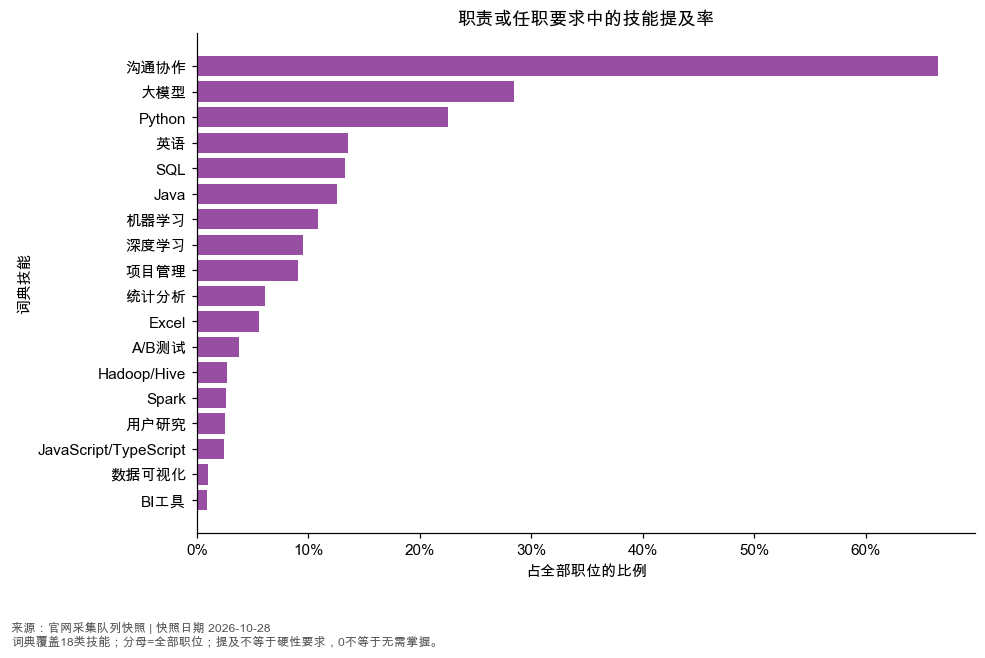

In [5]:
# 同时输出命中数、比例及要求文本分母，避免只给百分比而隐藏样本量。
skills_summary = pd.DataFrame({
    'skill': list(SKILLS), 'mentioned_jobs': combined.sum().values,
    'all_job_rate': combined.mean().values,
    'requirement_mentions': requirements.sum().values,
    'requirement_rate': requirements.loc[jobs.has_requirement].mean().values,
    'requirement_denominator': int(jobs.has_requirement.sum()),
}).sort_values('all_job_rate', ascending=False)
display(skills_summary.round(3))
# fig是整张图，ax是绘图区；figsize以英寸指定画布大小，后续save_figure统一添加来源注记。
fig, ax = plt.subplots(figsize=(9, 6))
v = skills_summary.iloc[::-1]
ax.barh(v.skill, v.all_job_rate, color='#984ea3')
from matplotlib.ticker import PercentFormatter
# 数据本身是0到1的小数，PercentFormatter(1)只把坐标标签显示成百分比。
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='职责或任职要求中的技能提及率', xlabel='占全部职位的比例', ylabel='词典技能')
save_figure(fig, '03_skill_mentions', '词典覆盖18类技能；分母=全部职位；提及不等于硬性要求，0不等于无需掌握。')
csv_export(skills_summary, '03_skill_mentions')

## 3. 聚焦数据相关岗位，比较公司与技能共现

先用标题正则筛选“数据分析/数据科学/数据挖掘/商业分析/商业智能”等候选，属于规则子集，
不是经过人工标注的完整岗位类别。对候选标题抽查后再解释结果。
跨公司对比只展示候选数≥20的公司，并保留各公司样本量。

,job_key,company_name,title_clean
30903,30904,快手,商业分析师（通用方向）-【商业化】
32944,32945,快手,数据分析实习生-社区治理
10551,10552,字节跳动,US大促数据科学实习生 - TikTok Shop
36956,36957,滴滴,IBG Food-商业分析实习生
12118,12119,字节跳动,数据科学 - 抖音增长
4046,4047,字节跳动,数据分析师-TikTok用户增长
18210,18211,腾讯,企业微信-数据分析师
2273,2274,字节跳动,风险数据分析专家 - 抖音社区治理
29579,29580,美团,中东商业分析实习生
9164,9165,字节跳动,体验运营（数据分析方向）-TikTok


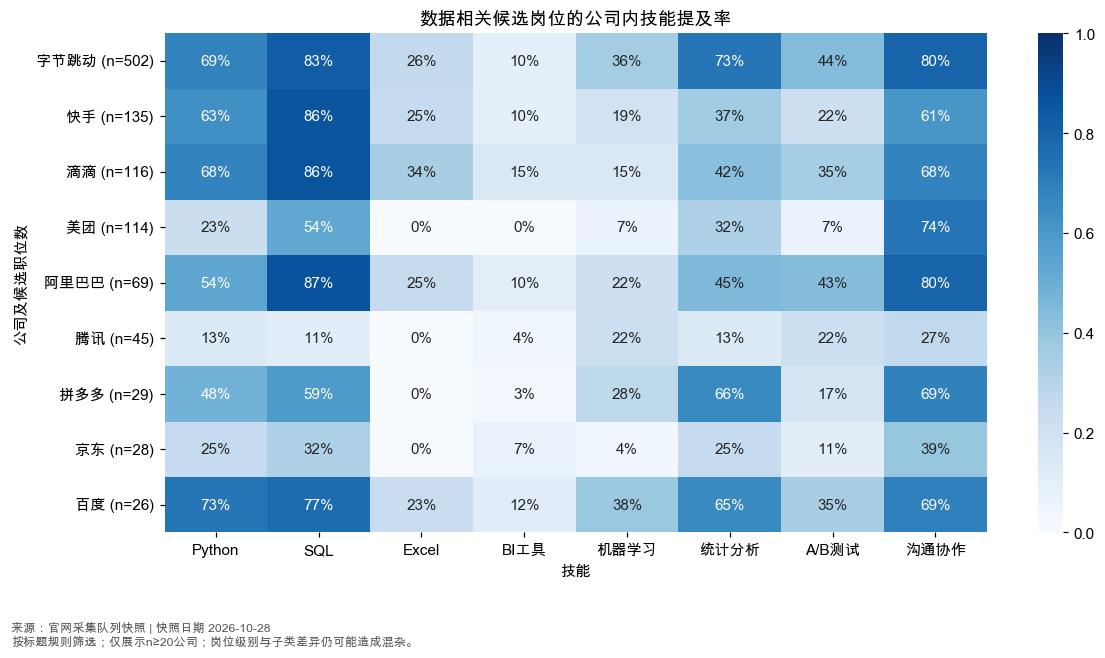

[Text(0.5, 1.0, '数据相关候选岗位的技能共现'),
 Text(0.5, 53.47256944444443, '技能'),
 Text(92.52256944444444, 0.5, '技能')]

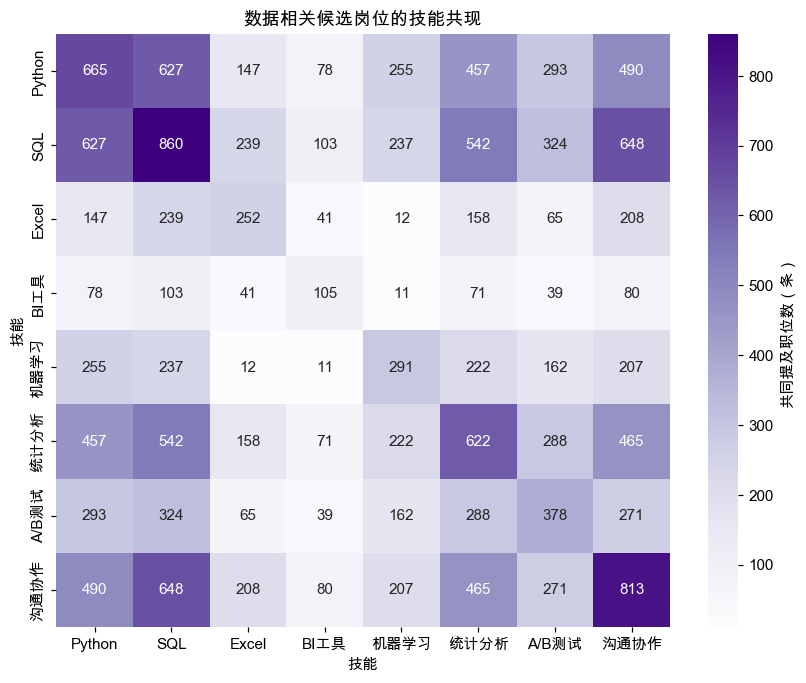

In [6]:
# 标题规则定义研究子集，case=False忽略英文大小写；na=False避免空标题进入布尔筛选错误。
jobs['focus_candidate'] = jobs['title_clean'].str.contains(FOCUS_PATTERN, case=False, regex=True, na=False)
# 研究对象从全量职位变为数据相关候选；后续提及率应使用这个子集自己的分母。
focus = jobs.loc[jobs.focus_candidate].copy()
assert len(focus) >= 50, '候选过少，请调整聚焦规则'
display(focus[['job_key', 'company_name', 'title_clean']].sample(min(12, len(focus)), random_state=SEED))
# 先记录各公司的候选样本量，再看技能比例；极小样本的百分比容易被误读。
focus_counts = focus.groupby('company_name').size().rename('n')
skill_cols = ['skill_' + s for s in SKILLS]
# 每列是0/1，所以公司内mean等于该技能在该公司候选中的提及率。
company_skills = focus.groupby('company_name')[skill_cols].mean()
# 公司至少20条候选才进入比较图；阈值是展示规则，不是统计显著性门槛。
eligible = focus_counts[focus_counts.ge(20)].sort_values(ascending=False).index
chosen_skills = ['Python', 'SQL', 'Excel', 'BI工具', '机器学习', '统计分析', 'A/B测试', '沟通协作']
fig, ax = plt.subplots(figsize=(11, 6))
view = company_skills.loc[eligible, ['skill_' + s for s in chosen_skills]].copy()
view.columns = chosen_skills
view.index = [f'{name} (n={focus_counts[name]})' for name in view.index]
sns.heatmap(view, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set(title='数据相关候选岗位的公司内技能提及率', xlabel='技能', ylabel='公司及候选职位数')
save_figure(fig, '03_focus_company_skills', '按标题规则筛选；仅展示n≥20公司；岗位级别与子类差异仍可能造成混杂。')
csv_export(company_skills.join(focus_counts).reset_index(), '03_focus_company_skills')

# 矩阵乘法会累加大量0/1，必须先转宽整数，不能让大于127的计数在int8里溢出。
binary = focus[['skill_' + s for s in chosen_skills]].astype('int64')
# T将职位×技能转成技能×职位；两矩阵相乘得到每对技能共同出现的职位数。
cooccurrence = binary.T @ binary  # 必须转int64，避免int8矩阵乘法溢出
cooccurrence.index = chosen_skills
cooccurrence.columns = chosen_skills
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Purples', ax=ax, cbar_kws={'label': '共同提及职位数（条）'})
ax.set(title='数据相关候选岗位的技能共现', xlabel='技能', ylabel='技能')

In [7]:
save_figure(fig, '03_skill_cooccurrence', '对角线=单技能提及数；非对角线=两技能同时提及数；不解释为因果。')
csv_export(cooccurrence.reset_index(names='skill'), '03_skill_cooccurrence')
# 每个技能与自己共现的次数，必须等于该技能单独命中的职位数。
assert np.array_equal(np.diag(cooccurrence), binary.sum().values)

## 3A. 【主线】宽表变长表：一条职位有多个技能

宽表适合机器学习：每个技能一列。长表适合统计：每条命中是一行“职位—技能”关系。
使用`melt`把技能列转成长表，再筛命中值1。长表行数是技能提及关系数，不是职位数。
顺便生成标题规则提示类别，用于对比技能侧重点；它不是官网统一职业分类。

In [8]:
# 保留所有命中提示与第一个提示；规则优先级公开，避免重叠类别被悄悄覆盖。
role_rules = [
    ('商业/经营分析', r'商业分析|经营分析|business intelligence'),
    ('数据挖掘', r'数据挖掘'),
    ('数据科学', r'数据科学|data scientist'),
    ('数据分析', r'数据分析|data analyst'),
]
def title_role_hints(title):
    return [label for label, pattern in role_rules if re.search(pattern, title, re.I)]

# 保留所有命中的提示类别；有重叠时不删除证据，主提示只是首个命中的教学约定。
role_lists = jobs.title_clean.map(title_role_hints)
jobs['role_hints_json'] = role_lists.map(lambda xs: json.dumps(xs, ensure_ascii=False))
jobs['role_hint_primary'] = role_lists.map(lambda xs: xs[0] if xs else '其他/未识别')
# 官网campus入口可能包含实习；保留标题提示来对照，而不是强行覆盖原始招聘类型。
jobs['title_internship_hint'] = jobs.title_clean.str.contains(
    r'实习|(?<![a-z])intern(?:ship)?(?![a-z])', case=False, regex=True, na=False)
jobs['internship_hint_outside_intern_type'] = (jobs.title_internship_hint &
    ~jobs.recruitment_type.isin(['internship', 'regular_intern', 'research_intern']))
display(pd.crosstab(jobs.recruitment_type, jobs.title_internship_hint).rename(columns={False: '无实习标题提示', True: '有实习标题提示'}))
csv_export(pd.crosstab(jobs.recruitment_type, jobs.title_internship_hint).reset_index(), '03_internship_title_vs_type')

# 限定数据相关候选生成长表，控制教学时的屏幕与内存规模。
# 研究对象从全量职位变为数据相关候选；后续提及率应使用这个子集自己的分母。
focus = jobs.loc[jobs.focus_candidate].copy()
skill_long = focus.melt(id_vars=['job_key', 'company_name', 'recruitment_type', 'role_hint_primary'],
                         value_vars=skill_cols, var_name='skill', value_name='mentioned')
skill_long = skill_long.loc[skill_long.mentioned.eq(1)].copy()
# 只移除字段名前缀，不修改技能名称本身；下划线之外的斜杠等合法名称仍保留。
skill_long['skill'] = skill_long['skill'].str.removeprefix('skill_')
assert len(skill_long) == int(focus['skill_count'].sum())
assert not skill_long.duplicated(['job_key', 'skill']).any()

title_internship_hint,无实习标题提示,有实习标题提示
recruitment_type,,
campus,3848,5175
dispatch,56,0
graduate,447,0
internship,68,2662
regular_intern,67,300
research_intern,15,241
society,27755,27


,job_key,company_name,recruitment_type,role_hint_primary,skill,mentioned
1,100,字节跳动,society,数据分析,Python,1
2,261,字节跳动,society,数据科学,Python,1
3,281,字节跳动,society,数据挖掘,Python,1
4,307,字节跳动,society,数据科学,Python,1
5,385,字节跳动,society,数据分析,Python,1
6,464,字节跳动,society,数据分析,Python,1
7,570,字节跳动,society,数据分析,Python,1
8,597,字节跳动,society,数据科学,Python,1
9,672,字节跳动,society,数据分析,Python,1
10,714,字节跳动,society,数据分析,Python,1


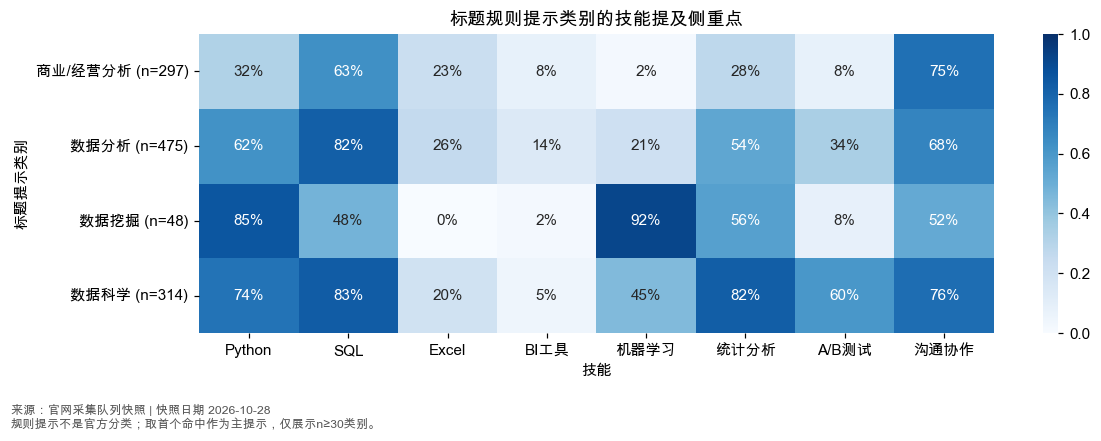

In [9]:
display(skill_long.head(10))
csv_export(skill_long, '03_focus_skill_long')

# 图只显示样本量足够的提示类别；未识别不强行推断归属。
role_n = focus.groupby('role_hint_primary').size()
role_profile = focus.groupby('role_hint_primary')[['skill_' + s for s in chosen_skills]].mean()
role_profile = role_profile.loc[role_n.ge(30)]
role_profile.columns = chosen_skills
fig, ax = plt.subplots(figsize=(11, 4))
role_profile.index = [f'{label} (n={role_n[label]})' for label in role_profile.index]
sns.heatmap(role_profile, annot=True, fmt='.0%', vmin=0, vmax=1, cmap='Blues', ax=ax)
ax.set(title='标题规则提示类别的技能提及侧重点', xlabel='技能', ylabel='标题提示类别')
save_figure(fig, '03_role_hint_skills', '规则提示不是官方分类；取首个命中作为主提示，仅展示n≥30类别。')
csv_export(focus.groupby('role_hint_primary')[skill_cols].mean().join(role_n.rename('n')).reset_index(), '03_role_hint_skills')

## 3B. 【拓展】共现多不等于关联强：条件概率、Jaccard与Lift

设A为提及Python，B为提及SQL：

| 指标 | 公式 | 回答的问题 |
|---|---|---|
| 共现数 | 同时提及A、B的职位数 | 数量有多少？ |
| P(B\|A) | AB共现数 / A提及数 | 提及A时，有多大比例也提及B？ |
| Jaccard | AB共现数 / A或B提及数 | 两组职位的重叠程度？ |
| Lift | P(AB) / [P(A)P(B)] | 比独立假设下预期共现多多少？ |

Lift>1不代表因果、技能互补或统计显著。稀有词的Lift可能很高，必须同时查看支持数。
这里只展示共同提及≥20条且两技能各自≥30条的组合，完整底稿保留所有技能对。

,a,b,n_a,n_b,n_ab,p_b_given_a,p_a_given_b,jaccard,lift
87,Spark,Hadoop/Hive,79,177,71,0.899,0.401,0.384,5.778
89,Spark,深度学习,79,50,20,0.253,0.400,0.183,5.762
108,机器学习,深度学习,291,50,48,0.165,0.960,0.164,3.754
117,深度学习,大模型,50,167,23,0.460,0.138,0.119,3.135
88,Spark,机器学习,79,291,58,0.734,0.199,0.186,2.871
99,Hadoop/Hive,深度学习,177,50,21,0.119,0.420,0.102,2.700
70,Excel,数据可视化,252,93,42,0.167,0.452,0.139,2.039
103,Hadoop/Hive,数据可视化,177,93,29,0.164,0.312,0.120,2.005
109,机器学习,大模型,291,167,76,0.261,0.455,0.199,1.780
62,Excel,BI工具,252,105,41,0.163,0.390,0.130,1.763


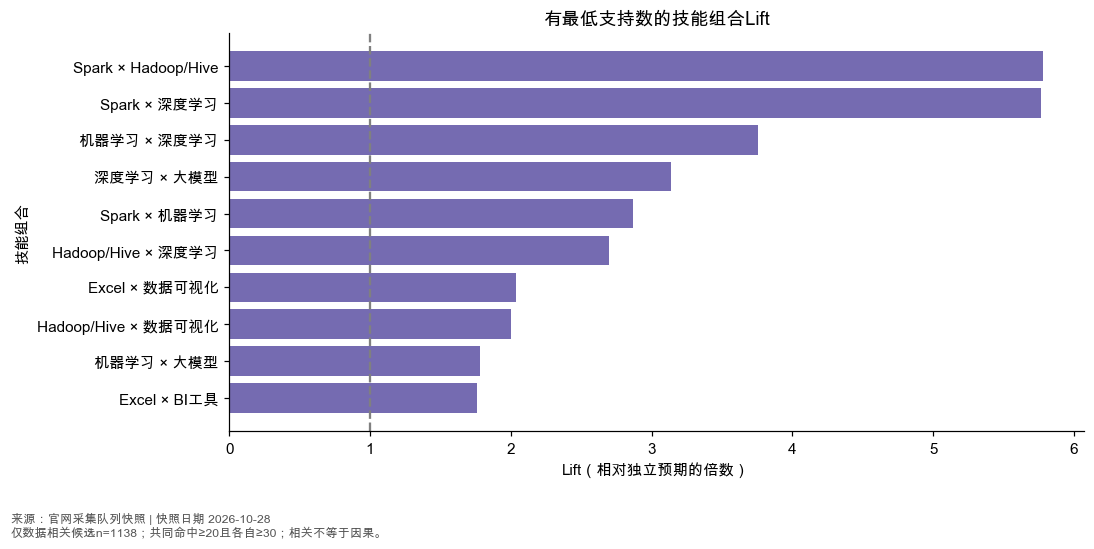

In [10]:
from itertools import combinations
pair_rows = []
# combinations只生成不重复的两两组合，不生成A-A，也不重复计算A-B和B-A。
for a, b in combinations(SKILLS, 2):
    a_mask, b_mask = focus['skill_' + a].eq(1), focus['skill_' + b].eq(1)
    n_a, n_b = int(a_mask.sum()), int(b_mask.sum())
    n_ab, n_union = int((a_mask & b_mask).sum()), int((a_mask | b_mask).sum())
    pair_rows.append({'a': a, 'b': b, 'n_a': n_a, 'n_b': n_b, 'n_ab': n_ab,
                      'p_b_given_a': n_ab / n_a if n_a else np.nan,
                      'p_a_given_b': n_ab / n_b if n_b else np.nan,
                      'jaccard': n_ab / n_union if n_union else np.nan,
                      'lift': n_ab * len(focus) / (n_a * n_b) if n_a and n_b else np.nan})
skill_pairs = pd.DataFrame(pair_rows)
supported_pairs = skill_pairs.loc[(skill_pairs.n_ab >= 20) & (skill_pairs.n_a >= 30) & (skill_pairs.n_b >= 30)]
# 支持数过滤后再排序，减少极少数命中带来的夸大；仍不能当作显著性检验。
supported_pairs = supported_pairs.sort_values('lift', ascending=False)
display(supported_pairs.head(10).round(3))
assert skill_pairs.jaccard.dropna().between(0, 1).all()
assert skill_pairs.p_b_given_a.dropna().between(0, 1).all()
assert (skill_pairs.n_ab <= skill_pairs[['n_a', 'n_b']].min(axis=1)).all()

top_pairs = supported_pairs.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_pairs.a + ' × ' + top_pairs.b, top_pairs.lift, color='#756bb1')
ax.axvline(1, color='gray', linestyle='--')
ax.set(title='有最低支持数的技能组合Lift', xlabel='Lift（相对独立预期的倍数）', ylabel='技能组合')
save_figure(fig, '03_skill_lift', f'仅数据相关候选n={len(focus)}；共同命中≥20且各自≥30；相关不等于因果。')
csv_export(skill_pairs, '03_skill_pairs')

## 3C. 【主线】新增语境列：明确要求、加分、否定和仅提及

“SQL加分”与“必须掌握SQL”不能使用同一个名称解释。下面用短语片段识别**语境提示**，
保存证据并保留“仅提及/多种语境”。这是可检查的规则，不是可靠的法律或招聘语义解析器。
同一句可能列出多个技能，修饰范围可能不清；因此输出叫“提示”，不要称为硬性要求标签。

In [11]:
# 返回“语境提示、命中证据”两个值；提示是启发式解释，必须能回到原句人工核验。
def requirement_context(text, skill):
    # 先按句号、分号、逗号分片；保留顿号，避免打断“熟练SQL、Python”的并列修饰。
    hits = []
    for sentence in re.split(r'[。；;，,\n]+', text):
        for match in re.finditer(SKILLS[skill], sentence, re.I):
            before_hit = sentence[max(0, match.start()-16):match.start()]
            after_hit = sentence[match.end():match.end()+16]
            context = before_hit + match.group() + after_hit
            # 否定提示先于熟悉/掌握等正向词判断；此处只处理匹配点前16字符的简单情形。
            if re.search(r'不要求|无需|不必', before_hit):
                label = '否定提示'
            # 出现加分/优先只记为提示，不把技能名称本身当作必需项。
            elif re.search(r'优先|加分', context):
                label = '加分提示'
            elif re.search(r'必须|熟练|精通|掌握|熟悉', before_hit):
                label = '明确要求提示'
            else:
                label = '仅提及'
            hits.append((label, context))
    if not hits:
        return '未提及', ''
    # 同一技能可能出现多个语境；用集合去重后，冲突保留为“多种语境”，而非任意覆盖。
    labels = sorted({label for label, _ in hits})
    return (labels[0] if len(labels) == 1 else '多种语境'), ' | '.join(context for _, context in hits)[:250]

# 先验证语义不同的最小例子，再对真实数据运行；这些断言不等于总体准确率评估。
assert requirement_context('不要求SQL经验', 'SQL')[0] == '否定提示'
assert requirement_context('有SQL能力加分', 'SQL')[0] == '加分提示'
assert requirement_context('熟练掌握SQL', 'SQL')[0] == '明确要求提示'
assert requirement_context('负责日报制作', 'SQL')[0] == '未提及'

In [12]:
for skill in ['Python', 'SQL', 'Excel']:
    extracted = jobs['requirement_clean'].map(lambda text: requirement_context(text, skill))
    # 元组第0项写成类别列，第1项写成证据列；分析和人工抽查都能使用。
    jobs['req_context_' + skill] = extracted.map(lambda pair: pair[0])
    jobs['req_evidence_' + skill] = extracted.map(lambda pair: pair[1])

context_table = pd.crosstab(jobs.recruitment_type, jobs.req_context_SQL)
display(context_table)
display(jobs.loc[jobs.req_context_SQL.eq('加分提示'), ['job_key', 'title_clean', 'req_evidence_SQL']].head(6))
csv_export(context_table.reset_index(), '03_sql_context_by_type')
csv_export(jobs[['job_key', 'title_clean', 'req_context_SQL', 'req_evidence_SQL']].sample(30, random_state=SEED), '03_context_review_sample')

req_context_SQL,仅提及,加分提示,多种语境,明确要求提示,未提及
recruitment_type,,,,,
campus,306,194,19,696,7808
dispatch,0,0,0,2,54
graduate,6,3,1,7,430
internship,183,163,17,368,1999
regular_intern,7,1,0,12,347
research_intern,4,0,1,4,247
society,741,313,136,2043,24549


,job_key,title_clean,req_evidence_SQL
81,82,商务策略专家（火山/BytePlus） - 火山引擎,会SQL/BI工具者优先
132,133,AI策略专家（社交投稿方向） - 抖音生态,具备SQL能力优先
206,207,销售支持-抖音生活服务（杭州）,会SQL优先考虑
226,227,直播分发策略产品经理 - 抖音直播,会使用SQL分析的优先
249,250,大盘战略分析师（竞争追踪与供给方向）-抖音生活服务,掌握SQL等数据处理工具优先
363,364,销售支持-抖音生活服务（上海）,会SQL优先考虑


## 4. 用 TF-IDF 探索词典外关键词

TF：词在职位文本中的频率；IDF：在很多职位中都出现的词权重更低。
先分词与停用词过滤，再提取候选岗位的平均 TF-IDF Top词。
这是一种探索分数，不是提及率，也不是技能重要性的客观分数。

In [13]:
stopwords = set('我们 你们 他们 以及 相关 工作 岗位 职责 要求 负责 具有 能够 良好 优秀 熟悉 优先 能力 以上 进行 包括 公司 团队 业务 经验 具备 使用 参与 通过 方向 支持 完成 基于 对于 了解 掌握 任职 本科 硕士 学历 职位'.split())
for word in ['数据分析', '商业分析', '数据科学', '数据挖掘', '机器学习', '深度学习', '用户增长', '实验设计', '数据仓库']:
    jieba.add_word(word)

# 分词函数决定模型“看见什么”；过滤规则会影响词表与结果，应与参数一起归档。
def tokenize(text):
    return [w for w in jieba.lcut(text.lower())
            if len(w.strip()) >= 2 and w not in stopwords
            and re.fullmatch(r'[a-z][a-z0-9_+#.-]*|[一-鿿]{2,}', w)]

vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, min_df=5, max_df=0.85, max_features=3000)
# fit学习本语料的词表与IDF，transform生成稀疏矩阵；行是职位，列是词项。
X = vectorizer.fit_transform(focus['analysis_text'])
keywords = pd.DataFrame({'term': vectorizer.get_feature_names_out(),
                         'mean_tfidf': np.asarray(X.mean(axis=0)).ravel()}).sort_values('mean_tfidf', ascending=False)
display(keywords.head(25))
csv_export(keywords, '03_tfidf_keywords')
print('候选职位×词项矩阵：', X.shape)

Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/3q/wv1kfqy544v7lnd3d_75mg3w0000gn/T/jieba.cache


Loading model cost 0.261 seconds.


Prefix dict has been built successfully.


,term,mean_tfidf
459,产品,0.054898
1338,数据分析,0.053015
1738,策略,0.050820
2141,问题,0.042934
15,ai,0.040585
...,...,...
1513,沟通,0.028523
2175,项目,0.028322
1644,电商,0.028086
1252,指标,0.027629


候选职位×词项矩阵： (1138, 2212)


## 4A. 【主线】词频和TF-IDF差在哪？用3条文本手算一次

词频只看出现次数；TF-IDF降低语料中常见词的权重。下面关闭归一化，观察原始权重。
scikit-learn默认平滑公式为`idf = log((1+文档数)/(1+含该词文档数)) + 1`。
默认TF-IDF还会做L2归一化，所以大语料中的得分不能直接当词频。

**思考**：如果所有职位都出现SQL，它的IDF会降到0吗？（此公式下为1。）

In [14]:
from sklearn.feature_extraction.text import CountVectorizer
toy_documents = ['python sql 数据分析', 'sql excel 业务分析', 'python 机器学习 模型']
# 教学示例已用空格分词，使用默认词项规则即可；不把它当作真实中文分词方案。
toy_counts = CountVectorizer()
toy_count_matrix = toy_counts.fit_transform(toy_documents)
# norm=None只为观察原始TF×IDF；真实模型默认还会把每行做L2归一化。
toy_tfidf = TfidfVectorizer(norm=None, smooth_idf=True)
toy_tfidf_matrix = toy_tfidf.fit_transform(toy_documents)
toy_terms = toy_tfidf.get_feature_names_out()
display(pd.DataFrame(toy_count_matrix.toarray(), columns=toy_counts.get_feature_names_out()).rename_axis('示例文档'))
display(pd.DataFrame(toy_tfidf_matrix.toarray(), columns=toy_terms).round(3).rename_axis('示例文档'))
doc_frequency = np.asarray((toy_tfidf_matrix > 0).sum(axis=0)).ravel()
manual_idf = np.log((1 + len(toy_documents)) / (1 + doc_frequency)) + 1
# 把手算公式与库输出比较，确认学生理解的是实际平滑公式，而非另一种教材约定。
assert np.allclose(manual_idf, toy_tfidf.idf_)
display(pd.DataFrame({'term': toy_terms, 'document_frequency': doc_frequency, 'idf': toy_tfidf.idf_}).round(3))

,excel,python,sql,业务分析,数据分析,机器学习,模型
示例文档,,,,,,,
0,0,1,1,0,1,0,0
1,1,0,1,1,0,0,0
2,0,1,0,0,0,1,1


,excel,python,sql,业务分析,数据分析,机器学习,模型
示例文档,,,,,,,
0,0.000,1.288,1.288,0.000,1.693,0.000,0.000
1,1.693,0.000,1.288,1.693,0.000,0.000,0.000
2,0.000,1.288,0.000,0.000,0.000,1.693,1.693


,term,document_frequency,idf
0,excel,1,1.693
1,python,2,1.288
2,sql,2,1.288
3,业务分析,1,1.693
4,数据分析,1,1.693
5,机器学习,1,1.693
6,模型,1,1.693


## 4B. 【拓展】特征覆盖率：提取了更多列，哪些列真的能使用？

分别查看原结构化学历、文本学历、文本经验的覆盖率。两种来源都应保留，
不能把文本提取结果无条件覆盖官网字段。覆盖率高也不等于准确率高。

In [15]:
feature_coverage = jobs.groupby('company_name').agg(
    n=('job_key', 'size'),
    structured_degree_rate=('required_degree', lambda s: s.fillna('').astype(str).str.strip().ne('').mean()),
    text_degree_rate=('degree_text', lambda s: s.ne('未抽取').mean()),
    text_experience_rate=('experience_years_min', lambda s: s.notna().mean()),
    explicit_sql_hint_rate=('req_context_SQL', lambda s: s.eq('明确要求提示').mean()),
)
display(feature_coverage.round(3))
csv_export(feature_coverage.reset_index(), '03_feature_coverage')
write_json(REPORTS / 'text_extension_metrics.json', {
    'focus_jobs': len(focus), 'long_skill_relations': len(skill_long),
    'skill_pairs': len(skill_pairs), 'supported_pairs': len(supported_pairs),
    'top_supported_pair': supported_pairs.iloc[0].to_dict(),
    'sql_context_counts': jobs.req_context_SQL.value_counts().to_dict(),
    'new_columns': ['role_hints_json', 'role_hint_primary', 'title_internship_hint', 'internship_hint_outside_intern_type'] + [prefix + skill for skill in ['Python', 'SQL', 'Excel']
                     for prefix in ['req_context_', 'req_evidence_']],
})

,n,structured_degree_rate,text_degree_rate,text_experience_rate,explicit_sql_hint_rate
company_name,,,,,
OPPO,273,0.546,0.593,0.066,0.029
京东,2025,0.000,0.223,0.030,0.015
哔哩哔哩,872,0.000,0.570,0.055,0.083
字节跳动,17053,0.000,0.797,0.022,0.085
小红书,1299,0.000,0.617,0.066,0.062
快手,2563,0.000,0.631,0.051,0.135
拼多多,767,0.000,0.445,0.116,0.068
携程,534,0.000,0.494,0.069,0.122
滴滴,1808,0.320,0.617,0.091,0.202


## 5. 人工抽查：规则验证不等于准确率验证

自动边界断言只证明规则按预期执行。没有人工标签，就不能报告精确率/召回率。
下面为每个技能抽取最多3个命中片段，保存核验表。教师/学生填写 `human_label`（1/0）与备注。
若要估计召回率，还须随机抽取未命中样本人工判断，不能只审核正例。

经验年限仅处理明确阿拉伯数字表达；“3年以下”是上限，不生成最低年限。
学历提取也是启发式，不覆盖所有英文或“本科/硕士”等复杂写法。请检查样本再使用。

In [16]:
# 核验表保留job_key、技能和命中片段，方便人判断正则究竟匹配到了什么。
audit_rows = []
for name, pattern in SKILLS.items():
    # 只抽命中正例可以检查误报；要评估漏报，还需额外抽取未命中样本人工判断。
    matched = jobs.loc[jobs['skill_' + name].eq(1)]
    for row in matched.sample(min(3, len(matched)), random_state=SEED).itertuples():
        # re.I忽略大小写；start/end给出字符位置，用于截取命中附近的原文证据。
        hit = re.search(pattern, row.analysis_text, re.I)
        audit_rows.append({'job_key': row.job_key, 'skill': name, 'title': row.title_clean,
                           'snippet': row.analysis_text[max(0, hit.start()-45):hit.end()+65],
                           'human_label': '', 'comment': ''})
audit = pd.DataFrame(audit_rows)
display(audit.head(12))
csv_export(audit, '03_skill_manual_audit')
# 对当前快照15条片段的教师参考审核；学生空白核验表另存，不被覆盖。
review = json.loads((ROOT / 'teacher_skill_review.json').read_text())
if review['snapshot_sha256'] == json.loads((DATA / 'raw' / 'manifest.json').read_text())['sha256']:
    teacher_review = audit.drop(columns=['human_label', 'comment']).merge(
        pd.DataFrame(review['rows']), on=['job_key', 'skill'], how='inner', validate='one_to_one')
    csv_export(teacher_review, '03_skill_teacher_review')
    display(teacher_review[['skill', 'snippet', 'human_label', 'comment']].head(6))
    print(review['scope'])
display(jobs.loc[jobs.experience_years_min.notna(), ['title_clean', 'requirement_clean', 'experience_years_min']].sample(
    min(8, jobs.experience_years_min.notna().sum()), random_state=SEED))

jobs.to_parquet(DATA / 'processed' / 'jobs_features.parquet', index=False)

,job_key,skill,title,snippet,human_label,comment
0,9767,Python,用户增长算法工程师-国际化短视频,提供增长动能。 1、具备强悍的编码能力和扎实的数据结构与算法功底，至少熟练掌握C/C++/python 等一种开发语言； ...,,
1,36758,Python,L Lab-算法实习生（2）,模型推理性能优化等大模型相关技术探索 （学历、目标院校、语言、技能、性格等要求） 1、熟悉python、java、c++等...,,
2,10192,Python,大语言模型算法实习生-Seed大模型人才实习,化、人工智能等相关专业优先； 2、优秀的代码能力、数据结构和基础算法功底，熟练C/C++或Python，ACM/ICPC、...,,
3,22789,SQL,阿里健康-数据开发-北京,位要求 1.3-5年以上数据研发经验； 2.技术基础扎实：熟练掌握java、python、sql中一种或多种数据处理语言等...,,
4,8047,SQL,印尼价格力策略运营-TikTok Shop,理、战略思维和策略分析能力，有经营分析、商业分析背景优先； 3、精通数据分析，能够熟练运用SQL、Python等工具进行深...,,
5,31342,SQL,质检运营专家（QA方向）,通过一定框架将问题归因清楚； 3、有优秀的数据敏感度和分析思维，能理解掌握业务指标逻辑，有SQL能力加分； 4、有较好的沟...,,
6,35694,Java,资深Java工程师-国际现金贷(北京上海杭州深圳),极与上下游团队沟通协作，推动项目落地。 1.统招本科及以上学历，计算机相关专业，3年及以上Java研发经验，扎实的编码及计...,,
7,7780,Java,AI研发效能工程师/架构师 - 计算,； 4、具备良好的工程实现能力，熟练掌握一门及以上开发语言（如Golang/Python/Java），能够独立推进系统或工...,,
8,40248,Java,CV算法工程师,学习和模式识别相关经验； 2、有一定的CV算法工作经验； 3、熟悉Linux系统，熟练使用Java/C++/Python其...,,
9,9328,JavaScript/TypeScript,AI原生安全智能体研发工程师-网络安全,以上相关研发经验（安全/网络/AI/Agent等方向）； 2、熟练掌握Go/Python/TypeScript中至少一门，...,,


,skill,snippet,human_label,comment
0,Python,提供增长动能。 1、具备强悍的编码能力和扎实的数据结构与算法功底，至少熟练掌握C/C++/python 等一种开发语言； ...,1,C/C++/Python等一种，属于可选语言集合，不是Python单项硬性要求
1,Python,模型推理性能优化等大模型相关技术探索 （学历、目标院校、语言、技能、性格等要求） 1、熟悉python、java、c++等...,1,python/java/c++的一种或多种，明确提及
2,Python,化、人工智能等相关专业优先； 2、优秀的代码能力、数据结构和基础算法功底，熟练C/C++或Python，ACM/ICPC、...,1,C/C++或Python，属于可选语言集合
3,SQL,位要求 1.3-5年以上数据研发经验； 2.技术基础扎实：熟练掌握java、python、sql中一种或多种数据处理语言等...,1,java/python/sql中一种或多种，明确提及
4,SQL,理、战略思维和策略分析能力，有经营分析、商业分析背景优先； 3、精通数据分析，能够熟练运用SQL、Python等工具进行深...,1,熟练运用SQL、Python，明确提及
5,SQL,通过一定框架将问题归因清楚； 3、有优秀的数据敏感度和分析思维，能理解掌握业务指标逻辑，有SQL能力加分； 4、有较好的沟...,1,有SQL能力加分，命中不应解释成硬性门槛


当前快照中15条命中片段的人工阅读；label=1仅确认该合并技能类别被提及，不代表必须要求；非盲评、非随机总体评估，不能据此估计精确率或召回率。


,title_clean,requirement_clean,experience_years_min
31538,廉正调查专家,1、5-10年以上相关工作经验（如反舞弊、合规、调查、廉洁从业、内审、稽查、监察、体制内公检法等），可以独立或带领团队完成...,5.0
6117,大模型产品经理-豆包,1、本科及以上学历，3年以上产品工作经验，有大语言模型、AI对话等产品经历优先； 2、了解LLM的技术原理和进展，熟悉海内...,3.0
36302,资深数据产品（开发方向）,1、3年以上数据产品工作经验，具有开发平台相关产品建设经验； 2、本科及以上学历，计算机/信息系统相关专业优先； 3、对H...,3.0
20007,全球速卖通事业部(AliExpress)-增长解决方案专家-杭州,1、本科及以上学历，国际物流、仓储相关专业。 2、3年以上相关工作经验，有互联网行业履约解决方案经验者优先。 3、具有敏锐...,3.0
31911,推荐算法工程师-【实时内容推荐】,1、计算机、数学或统计学相关专业，具备良好的逻辑思维能力、扎实的数据结构和算法功底，具备良好的沟通协作能力； 2、在互联网...,1.0
26319,公司金融岗,1.学历：统招本科及以上学历，法学、法律硕士（LLM/JD）或法律+财务/金融复合背景优先； 2.经验：5-10年工作经验...,5.0
22023,高德销服科技-美食交易-南区渠道经理-专项-广州,"1、5年以上相关行业经验，2年以上的团队管理经验； 2、熟悉本地生活，有O2O，互联网工作经验；对渠道, 生态管理等有比较...",5.0
33751,法务BP（广告商业化方向）,1、法学专业全日制本科及以上学历； 2、5年左右工作经验； 3、具有优秀的中英文书写能力和表达能力； 4、对品牌广告、效果...,5.0


In [17]:
write_json(REPORTS / 'text_metrics.json', {
    'focus_candidates': len(focus), 'all_jobs': len(jobs), 'skills': len(SKILLS),
    'with_requirement': int(jobs.has_requirement.sum()),
    'experience_extracted': int(jobs.experience_years_min.notna().sum()),
    'focus_python_rate': float(focus['skill_Python'].mean()),
    'focus_sql_rate': float(focus['skill_SQL'].mean()),
    'tfidf_features': X.shape[1], 'manual_audit_rows': len(audit),
})

## 课堂练习与验收

1. 新增“Git”技能，先写正例/反例，再统计；不要让 GitHub/GitLab 是否算别名成为隐含规则。
2. SQL 是硬性要求还是加分项？现有0/1列不能区分，尝试定位包含它的句子。
3. 完成核验表的10条人工判断，记录误报原因，修改词典并重新运行。
4. 比较职责提及率与要求提及率时，明确分母。不要把共现图称为因果关系。

**验收**：边界断言通过；共现对角线等于单技能计数；特征表可回溯 `job_key`；无虚构准确率。
输出：技能特征表、3 张图、关键词底稿、待人工标注核验表。